In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

## O objetivo desse notebook é testar as funções que usaremos, criar os seus arquivos .py e colocar no github na pasta 'test'.

In [ ]:
# Definindo um ativo
ativo='BBDC4.SA'

# definindo uma carteira
ativos='ITUB4.SA','BBDC4.SA','BBAS3.SA','SANB11.SA','WEGE3.SA'

In [ ]:
df = yf.download(ativos, start='2020-01-01', end='2026-11-01')
print(df.head(10))

print(f'As colunas do df são: \n {df.columns}')



/tmp/ipykernel_901/1390310712.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ativos, start='2020-01-01', end='2026-11-01')
[*********************100%***********************]  5 of 5 completed


Price           Close                                                   High  \
Ticker       BBAS3.SA   BBDC4.SA   ITUB4.SA  SANB11.SA   WEGE3.SA   BBAS3.SA   
Date                                                                           
2020-01-02  16.931360  18.166973  22.926022  30.509237  15.458447  16.984861   
2020-01-03  16.903038  18.176157  22.684893  30.491304  15.261049  16.965980   
2020-01-06  16.679592  17.851498  22.347294  29.666199  15.300529  16.805476   
2020-01-07  16.553713  17.541378  21.828852  29.603756  15.418969  16.689038   
2020-01-08  16.402649  17.270018  21.473183  29.372717  14.835545  16.676447   
2020-01-09  16.069057  16.993813  21.045170  28.816986  14.616213  16.468738   
2020-01-10  15.691406  16.683699  20.858273  28.692097  14.914509  16.188646   
2020-01-13  15.867642  16.862976  21.135588  29.048019  15.054876  15.892820   
2020-01-14  15.782665  16.843594  21.135588  28.648396  15.353167  15.889666   
2020-01-15  15.493138  16.547998  20.876

In [ ]:
# Separando os dados de cada banco
bbas3 = df.xs('BBAS3.SA', level='Ticker', axis=1)
bbdc4 = df.xs('BBDC4.SA', level='Ticker', axis=1)
itub4 = df.xs('ITUB4.SA', level='Ticker', axis=1)
sanb11= df.xs('SANB11.SA',  level='Ticker',axis=1)



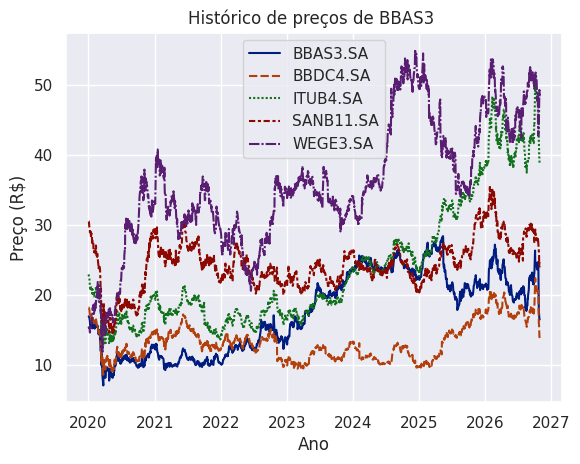

In [ ]:
sns.set_theme(style='darkgrid')
sns.lineplot(df['Close'],palette='dark')
plt.title('Histórico de preços de BBAS3 ')
plt.xlabel('Ano')
plt.legend()
plt.ylabel('Preço (R$)')


plt.show()

In [ ]:
# Retorno esperado do ativo

# definir data

def retorno_historico_ativo(preco_atual, preco_anterior):
    return (preco_atual - preco_anterior) / preco_anterior

retorno_itub4 = itub4['Close'].pct_change().mean()
retorno_bbas3 = bbas3['Close'].pct_change().mean()


print(retorno_itub4)
print(retorno_bbas3)



0.0004949462906491788
0.00026292924488290856


In [ ]:
# criando uma carteira e chutando pesos e riscos
w1 = np.linspace(0, 1, 1000)
w2 = 1 - w1


retorno_carteiras = w1 * retorno_itub4 + w2 * retorno_bbas3


#desvio padrão dos retornos
sigma_itub = retorno_itub4.std()
sigma_bb = retorno_bbas3.std()

# cov entre retornos
covariancia = itub4['Close'].pct_change().cov(bbas3['Close'].pct_change())

#risco da carteira
variancia = np.sqrt(
    (w1**2 * sigma_itub**2) +
    (w2**2 * sigma_bb**2) +
    (2 * w1 * w2 * covariancia)
)



# 4. Cálculo do RISCO da carteira (Desvio-Padrão)
risco_carteiras = np.sqrt(
    (w1**2 * sigma_itub**2) +
    (w2**2 * sigma_bb**2) +
    (2 * w1 * w2 * covariancia)
)



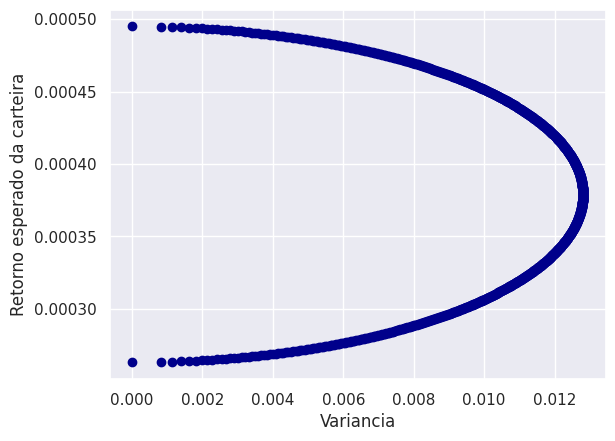

In [ ]:
# chutando risco
plt.scatter(variancia,retorno_carteiras,color='darkblue')
plt.xlabel('Variancia')
plt.ylabel('Retorno esperado da carteira')
plt.show()
